In [ ]:
# general imports

import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

import matplotlib.pyplot as plt
import matplotlib as mpl

import pandas as pd
import seaborn as sns

In [ ]:
# pyCRLD imports

# Agents
from pyCRLD.Agents.Base import abase
from pyCRLD.Agents.StrategySARSA import stratSARSA

# Environments
from pyCRLD.Environments.SocialDilemma import SocialDilemma
from pyCRLD.Environments.RiskRewardDilemma import RiskRewardDilemma
from pyCRLD.Environments.DistTwoArmedBanditOneState import DistTwoArmedBanditOneState

# Utilities
from pyCRLD.Utils.Helpers import *
from pyCRLD.Utils.Trajectories1D import trajectories_1D 
from pyCRLD.Utils.PhasePlot import phaseplot, _data_to_plot, _strategies, _dXisa_s
from pyCRLD.Utils import FlowPlot as fp

In [ ]:
# DDRL imports

from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA

In [ ]:
# two-armed bandit task
xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.7, 0.3],
               [0.9, 0.1]])
envTAB = DistTwoArmedBanditOneState(disttype='discrete', xs=xs, ps=ps)

# RR dilemma
envRR = RiskRewardDilemma(pc=0.1, pr=0.2, rc=0.5, rr=1, rd=0)

# Stag-Hunt game
envSH = SocialDilemma(R=3, P=0, S=-2, T=1)

envs = [envTAB, envRR, envSH]

In [ ]:
quantiles = [0.25, 0.5, 0.75]
expectiles = [0.25, 0.5, 0.75]
weights = [0.25, 1., 4.]

bias_params = np.array([quantiles, 
                        expectiles, 
                        weights])

methods = ["quantile", "expectile", "weights"]

betas = [4, 50, 50]

Rmins = [-1, 0, -2]
Rmaxs = [1, 1, 3]

Xs = np.linspace(0, 1, 11)
Xs[0] = 0.0001
Xs[-1] = 0.9999

gammas = [0, 0.9, 0.9]
pref = [False, True, True]

In [ ]:
deltaQs = np.zeros((3, 3, 3, len(Xs)))
for i in range(3):
    env = envs[i]
    beta = betas[i]
    Rmin = Rmins[i]
    Rmax = Rmaxs[i]
    Xini = np.ones((env.N, env.Z, env.M)) * 0.5
    if i == 1:
        Xini[:, 1, 0] = 1
        Xini[:, 1, 1] = 0
    for j in range(3):
        param = bias_params[j]
        method = methods[j]
        for k in range(3):
            tau = param[k]
            w = param[k]
            db = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                            learning_rates=0.1, discount_factors=gammas[i], 
                            choice_intensities=beta, Rmin=Rmin, Rmax=Rmax,
                            method=method, tau=tau, wU=w, use_prefactor=pref[i])
            for ind, X in enumerate(Xs):
                Xini[0, 0, 0] = X
                Xini[0, 0, 1] = 1 - X
                if i == 2:
                    Xini[1, 0, 0] = X
                    Xini[1, 0, 1] = 1 - X
                Q0 = db._Qisa(Xini)[0, 0, 0]
                Q1 = db._Qisa(Xini)[0, 0, 1]
                deltaQ = Q0 - Q1
                deltaQs[i, j, k, ind] = deltaQ

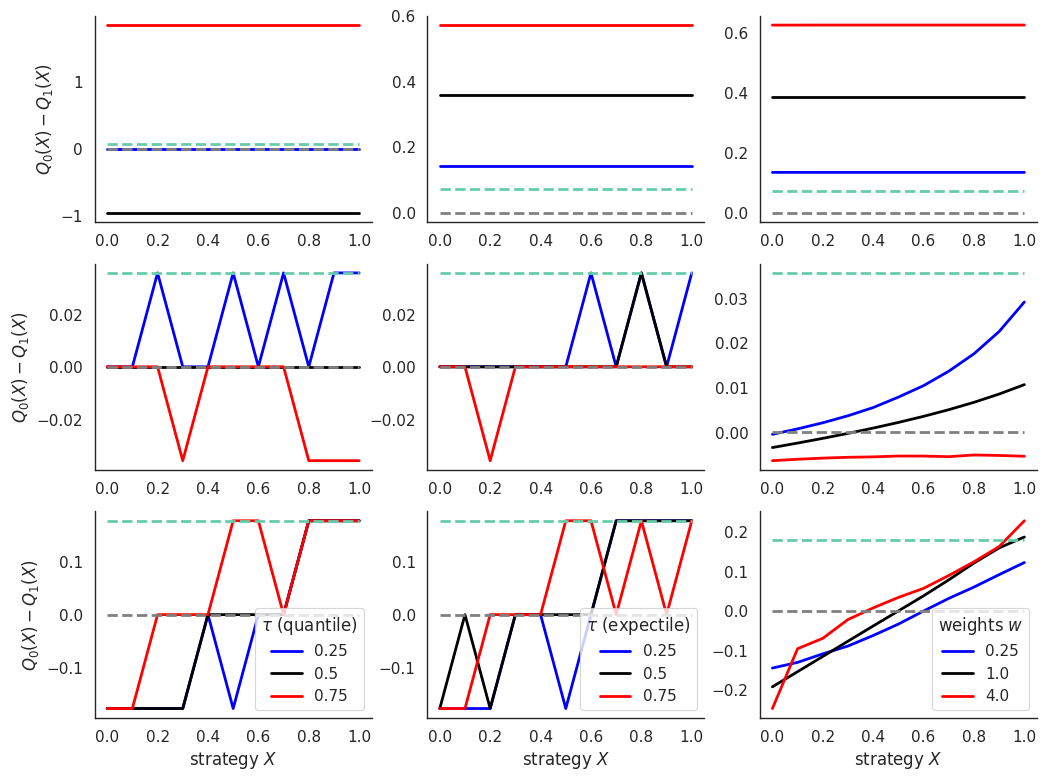

In [ ]:
titles = [r'$\tau$'+' (quantile)', r'$\tau$'+' (expectile)', 'weights '+r'$w$']

sns.set_style("white")
sns.set_context("paper", font_scale=1.25, rc={"lines.linewidth": 2})
fig, ((ax1, ax2, ax3), 
      (ax4, ax5, ax6),
      (ax7, ax8, ax9)) = plt.subplots(3, 3, figsize=(3.2 * 3.8, 2.4 * 3.8))
axes = [[ax1, ax2, ax3],
       [ax4, ax5, ax6],
       [ax7, ax8, ax9]]

colors = ['blue', 'black', 'red']

for i in range(3):
    grid = np.linspace(Rmins[i], Rmaxs[i], 29)
    wdth = grid[1] - grid[0]
    for j in range(3):
        for k in range(3):
            axes[i][j].plot(Xs, deltaQs[i, j, k, :], color=colors[k], 
                            label=str(bias_params[j][k]))
        axes[i][j].plot(Xs, np.zeros((len(Xs))), ls='--', color='gray')
        axes[i][j].plot(Xs, np.ones((len(Xs))) * wdth, ls='--', color='mediumaquamarine')
        sns.despine(ax=axes[i][j], top=True, right=True)
        if i == 2:
            axes[2][j].set_xlabel('strategy '+r'$X$')
            axes[2][j].legend(title=titles[j])
    axes[i][0].set_ylabel(r'$Q_0(X) - Q_1(X)$')
        
